In [ ]:
   !unzip -q -o keystroke-dynamics-project.zip
   %cd keystroke-dynamics-project/notebooks

unzip:  cannot find or open keystroke-dynamics-project.zip, keystroke-dynamics-project.zip.zip or keystroke-dynamics-project.zip.ZIP.
[Errno 2] No such file or directory: 'keystroke-dynamics-project/notebooks'
/content/keystroke-dynamics-project/notebooks


# Task 1: Keystroke Identification (Person A)
**Question:** given one typing sample of `.tie5Roanl` (31 timing features), which of the 51 users typed it?

**Contract (frozen in `split.txt`):** train = sessions 1-4 (200 reps/user), test = sessions 5-8 (200 reps/user).
The test set is touched once per model. Hyperparameters are fixed up front, and for the deep models the epoch count is chosen on a validation slice of the *training* sessions (session 4), never on test.

Results are appended to `../results.csv` as `(model, task, metric, value)`.

Sections: 1 Setup · 2 EDA · 3 Features · 4 Classical models · 5 Deep models · 6 Ablations · 7 Error analysis · 8 Summary

In [ ]:
import os, sys, random, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)
from metrics import append_result, load_split   # shared contract file, never edited

CFG = load_split()
SEED = CFG["SEED"]
np.random.seed(SEED); random.seed(SEED)

DATA = os.environ.get("KD_DATA", os.path.join(ROOT, "data", "DSL-StrongPasswordData.csv"))
RESULTS_PATH = os.environ.get("KD_RESULTS", os.path.join(ROOT, "results.csv"))
TASK = "task1_identification"

# Re-running the notebook must not duplicate rows: drop only THIS task's old rows.
if os.path.exists(RESULTS_PATH):
    _r = pd.read_csv(RESULTS_PATH)
    _r[_r.task != TASK].to_csv(RESULTS_PATH, index=False)
print("split:", {k: CFG[k] for k in ("TRAIN_SESSIONS", "TEST_SESSIONS")}, "| seed", SEED)

split: {'TRAIN_SESSIONS': [1, 2, 3, 4], 'TEST_SESSIONS': [5, 6, 7, 8]} | seed 42


## 1. Load data and apply the frozen split

In [ ]:
df = pd.read_csv(DATA)
feat_cols = [c for c in df.columns if c not in ("subject", "sessionIndex", "rep")]
assert len(feat_cols) == 31 and df[feat_cols].isna().sum().sum() == 0
assert df.subject.nunique() == 51 and (df.groupby("subject").size() == 400).all()

H_idx  = [i for i, c in enumerate(feat_cols) if c.startswith("H.")]
DD_idx = [i for i, c in enumerate(feat_cols) if c.startswith("DD.")]
UD_idx = [i for i, c in enumerate(feat_cols) if c.startswith("UD.")]
assert (len(H_idx), len(DD_idx), len(UD_idx)) == (11, 10, 10)

classes = sorted(df.subject.unique())
label = {s: i for i, s in enumerate(classes)}
train = df[df.sessionIndex.isin(CFG["TRAIN_SESSIONS"])].reset_index(drop=True)
test  = df[df.sessionIndex.isin(CFG["TEST_SESSIONS"])].reset_index(drop=True)
ytr, yte = train.subject.map(label).values, test.subject.map(label).values
print(df.shape, "| train", train.shape, "| test", test.shape)
print("train reps per user:", train.groupby("subject").size().unique(), "| test:", test.groupby("subject").size().unique())

(20400, 34) | train (10200, 34) | test (10200, 34)
train reps per user: [200] | test: [200]


## 2. EDA

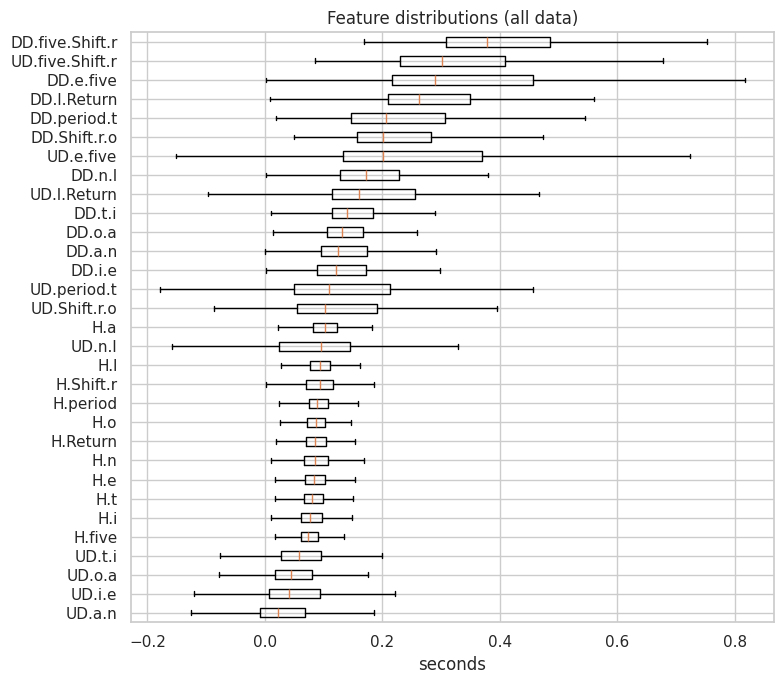

max |DD - UD - H| = 0.0
numerical rank of the 31 features: 21 (tree models don't care; LR/Mahalanobis do)
fraction of negative UD (key overlap): 0.1084


In [ ]:
# 2.1 Scale of each feature: DD/UD around the 5th and 6th keystrokes are far larger (the pause mid-password)
fig, ax = plt.subplots(figsize=(8, 7))
order = np.argsort(df[feat_cols].median().values)
ax.boxplot([df[feat_cols[i]].clip(upper=3) for i in order], vert=False, showfliers=False)
ax.set_yticklabels([feat_cols[i] for i in order])
ax.set_xlabel("seconds"); ax.set_title("Feature distributions (all data)")
plt.tight_layout(); plt.show()

# 2.2 Structural redundancy: DD = H(key1) + UD for every digraph
resid = np.abs(df[[feat_cols[i] for i in DD_idx]].values - df[[feat_cols[i] for i in UD_idx]].values - df[[feat_cols[i] for i in H_idx[:10]]].values)
print("max |DD - UD - H| =", resid.max().round(6))
rank = np.linalg.matrix_rank(df[feat_cols].values - df[feat_cols].values.mean(0))
print("numerical rank of the 31 features:", rank, "(tree models don't care; LR/Mahalanobis do)")
print("fraction of negative UD (key overlap):", (df[[feat_cols[i] for i in UD_idx]] < 0).values.mean().round(4))

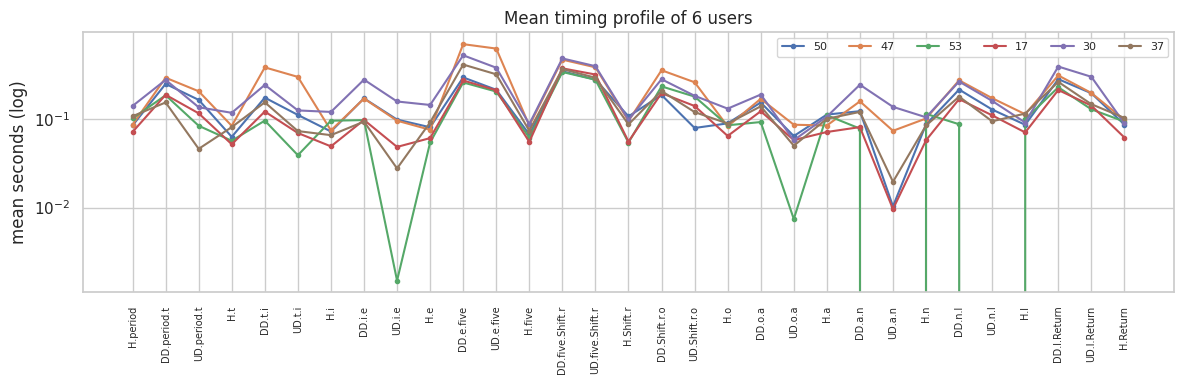

Most discriminative:
 H.t          638.5
H.Shift.r    623.6
H.i          445.4
H.e          371.6
H.l          366.5
H.period     362.1
H.n          328.8
H.o          317.8

Least discriminative:
 UD.t.i    85.8
DD.a.n    85.5
DD.t.i    80.1
UD.i.e    28.1
DD.i.e    26.3


In [ ]:
# 2.3 The "fingerprint": mean profile of 6 users across the 31 features
rng = np.random.RandomState(SEED)
demo_users = rng.choice(classes, 6, replace=False)
prof = df[df.subject.isin(demo_users)].groupby("subject")[feat_cols].mean()
fig, ax = plt.subplots(figsize=(12, 4))
for u in demo_users:
    ax.plot(range(31), prof.loc[u].values, marker="o", ms=3, label=u)
ax.set_xticks(range(31)); ax.set_xticklabels(feat_cols, rotation=90, fontsize=7)
ax.set_yscale("log"); ax.set_ylabel("mean seconds (log)"); ax.legend(ncol=6, fontsize=8)
ax.set_title("Mean timing profile of 6 users"); plt.tight_layout(); plt.show()

# 2.4 Between-user vs within-user separation per feature (ANOVA F on train)
F, _ = f_classif(train[feat_cols].values, ytr)
fs = pd.Series(F, index=feat_cols).sort_values(ascending=False)
print("Most discriminative:\n", fs.head(8).round(1).to_string())
print("\nLeast discriminative:\n", fs.tail(5).round(1).to_string())

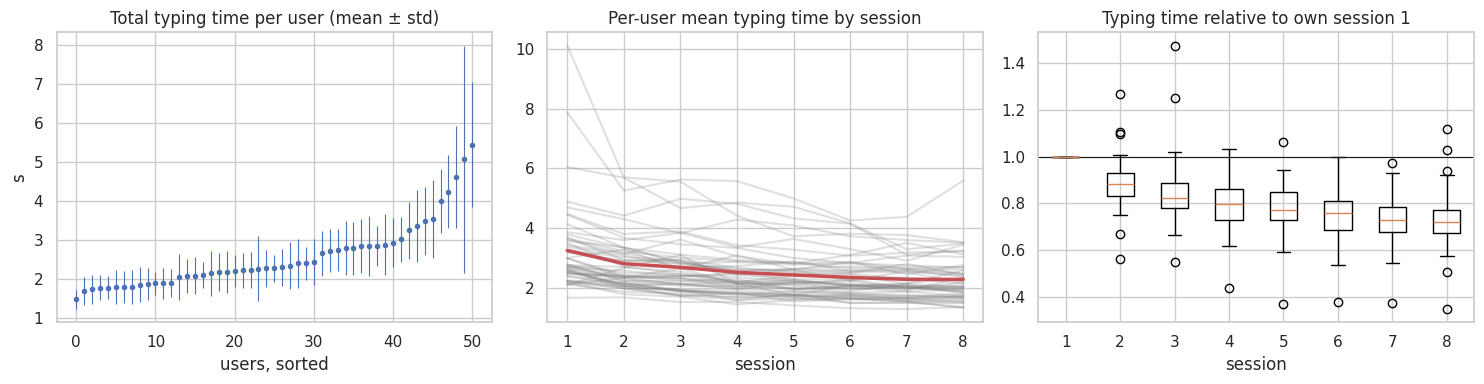

Mean speed-up vs session 1, sessions 5-8: [-0.229 -0.25  -0.27  -0.273]


In [ ]:
# 2.5 Between-user vs within-user variation, and session drift
DDc = [feat_cols[i] for i in DD_idx]
df["total_time"] = df[DDc].sum(axis=1) + df["H.Return"]      # first press to last release

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
um = df.groupby("subject").total_time.agg(["mean", "std"]).sort_values("mean")
axes[0].errorbar(range(51), um["mean"], yerr=um["std"], fmt="o", ms=3, lw=0.8)
axes[0].set_title("Total typing time per user (mean ± std)"); axes[0].set_xlabel("users, sorted"); axes[0].set_ylabel("s")

sm = df.groupby(["subject", "sessionIndex"]).total_time.mean().unstack()
sm.T.plot(ax=axes[1], legend=False, alpha=0.25, color="gray")
sm.mean().plot(ax=axes[1], color="C3", lw=2.5)
axes[1].set_title("Per-user mean typing time by session"); axes[1].set_xlabel("session")

rel = sm.div(sm[1], axis=0)
axes[2].boxplot([rel[s] for s in range(1, 9)]); axes[2].set_xticklabels(range(1, 9)); axes[2].axhline(1, c="k", lw=0.8)
axes[2].set_title("Typing time relative to own session 1"); axes[2].set_xlabel("session")
plt.tight_layout(); plt.show()
print("Mean speed-up vs session 1, sessions 5-8:", (rel[[5, 6, 7, 8]].mean().values - 1).round(3))

**What the EDA is telling us (fill in your own reading after running):** how big is between-user spread relative to within-user spread? Do users get faster across sessions (typing-time drift matters because we train on sessions 1-4 and test on 5-8)? Which keystrokes carry the most signal?

## 3. Features

In [ ]:
def add_derived(d):
    X = d[feat_cols].copy()
    Hc  = [feat_cols[i] for i in H_idx]
    DDc_ = [feat_cols[i] for i in DD_idx]
    UDc = [feat_cols[i] for i in UD_idx]
    X["total_time"] = d[DDc_].sum(axis=1) + d["H.Return"]
    X["speed_keys_per_s"] = 11.0 / X["total_time"]
    for n, cols in (("H", Hc), ("DD", DDc_), ("UD", UDc)):
        X[f"mean_{n}"] = d[cols].mean(axis=1)
        X[f"std_{n}"]  = d[cols].std(axis=1)
    X["n_overlaps"] = (d[UDc] < 0).sum(axis=1)
    X["ratio_H_DD"] = X["mean_H"] / X["mean_DD"]
    return X

# Main experiments use the 31 raw features. Global scaler is fit on TRAIN ONLY.
Xtr_raw, Xte_raw = train[feat_cols].values, test[feat_cols].values
scaler = StandardScaler().fit(Xtr_raw)
Xtr, Xte = scaler.transform(Xtr_raw), scaler.transform(Xte_raw)

def to_seq(X):
    # (N, 11 keystrokes, 3 channels): hold, down-down to next key, up-down to next key; last key has no next -> 0
    S = np.zeros((len(X), 11, 3), dtype=np.float32)
    S[:, :, 0] = X[:, H_idx]; S[:, :10, 1] = X[:, DD_idx]; S[:, :10, 2] = X[:, UD_idx]
    return S
Str, Ste = to_seq(Xtr), to_seq(Xte)
print("tabular", Xtr.shape, "| sequence", Str.shape)

tabular (10200, 31) | sequence (10200, 11, 3)


## 4. Classical models

In [ ]:
RESULTS, MODELS = {}, {}

def report(name, y_pred, extra=""):
    acc = accuracy_score(yte, y_pred); f1 = f1_score(yte, y_pred, average="macro")
    RESULTS[name] = dict(accuracy=acc, macro_f1=f1, pred=np.asarray(y_pred))
    append_result(name, TASK, "accuracy", acc, path=RESULTS_PATH)
    append_result(name, TASK, "macro_f1", f1, path=RESULTS_PATH)
    print(f"{name:<24} acc={acc:.4f}  macroF1={f1:.4f}  {extra}")

def run_sk(name, model, Xa, Xb):
    t = time.time(); model.fit(Xa, ytr); MODELS[name] = model
    report(name, model.predict(Xb), f"({time.time() - t:.0f}s)")

run_sk("LogisticRegression", LogisticRegression(C=10, max_iter=3000), Xtr, Xte)
run_sk("SVM-RBF", SVC(C=10, kernel="rbf", gamma="scale"), Xtr, Xte)
run_sk("RandomForest", RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED), Xtr, Xte)

LogisticRegression       acc=0.6913  macroF1=0.6854  (6s)
SVM-RBF                  acc=0.7616  macroF1=0.7573  (8s)
RandomForest             acc=0.8183  macroF1=0.8144  (24s)


In [ ]:
from xgboost import XGBClassifier
run_sk("XGBoost", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                                colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=SEED), Xtr, Xte)

XGBoost                  acc=0.8051  macroF1=0.8028  (30s)


## 5. Deep models
Epoch count is picked on session 4 (held out of an inner training run on sessions 1-3), then the model is retrained on all of sessions 1-4 for that many epochs and scored once on test.

In [ ]:
import torch, torch.nn as nn
device = "cuda" if torch.cuda.is_available() else "cpu"
N_CLS = len(classes)
print("device:", device)

def predict(m, X):
    m.eval()
    with torch.no_grad():
        out = [m(torch.as_tensor(X[i:i + 2048], dtype=torch.float32, device=device)).argmax(1).cpu() for i in range(0, len(X), 2048)]
    return torch.cat(out).numpy()

def train_net(model_fn, X, y, epochs, Xv=None, yv=None, lr=2e-3, wd=1e-3, bs=128):
    torch.manual_seed(SEED)
    m = model_fn().to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.CrossEntropyLoss(label_smoothing=0.05)
    Xt = torch.as_tensor(X, dtype=torch.float32, device=device); yt = torch.as_tensor(y, dtype=torch.long, device=device)
    hist = []
    for _ in range(epochs):
        m.train()
        perm = torch.randperm(len(Xt), device=device)
        for i in range(0, len(Xt), bs):
            idx = perm[i:i + bs]
            if len(idx) < 2: continue                      # BatchNorm needs >1 sample
            opt.zero_grad(); lossf(m(Xt[idx]), yt[idx]).backward(); opt.step()
        if Xv is not None:
            hist.append(accuracy_score(yv, predict(m, Xv)))
    return m, hist

def run_dl(name, model_fn, Xa, Xb, max_epochs=80, **kw):
    t = time.time()
    sess = train.sessionIndex.values
    val = sess == max(CFG["TRAIN_SESSIONS"])
    _, hist = train_net(model_fn, Xa[~val], ytr[~val], max_epochs, Xa[val], ytr[val], **kw)
    best = int(np.argmax(hist)) + 1
    m, _ = train_net(model_fn, Xa, ytr, best, **kw)
    MODELS[name] = m
    report(name, predict(m, Xb), f"(epochs={best}, val_acc={max(hist):.3f}, {time.time() - t:.0f}s)")
    return hist

class MLP(nn.Module):
    def __init__(self, d=31, h=256, p=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p),
                                 nn.Linear(h, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, N_CLS))
    def forward(self, x): return self.net(x)

class CNN1D(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(3, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
                                  nn.Conv1d(64, 128, 3, padding=1), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128 * 11, 256), nn.ReLU(), nn.Dropout(p), nn.Linear(256, N_CLS))
    def forward(self, x): return self.head(self.conv(x.transpose(1, 2)))

class BiLSTM(nn.Module):
    def __init__(self, h=128, p=0.3):
        super().__init__()
        self.lstm = nn.LSTM(3, h, num_layers=2, batch_first=True, bidirectional=True, dropout=p)
        self.head = nn.Sequential(nn.Dropout(p), nn.Linear(4 * h, N_CLS))
    def forward(self, x):
        o, _ = self.lstm(x)
        return self.head(torch.cat([o.mean(1), o.max(1).values], 1))

device: cpu


MLP                      acc=0.8420  macroF1=0.8386  (epochs=78, val_acc=0.890, 53s)
1D-CNN                   acc=0.8571  macroF1=0.8534  (epochs=79, val_acc=0.911, 258s)
BiLSTM                   acc=0.7492  macroF1=0.7450  (epochs=77, val_acc=0.822, 1162s)


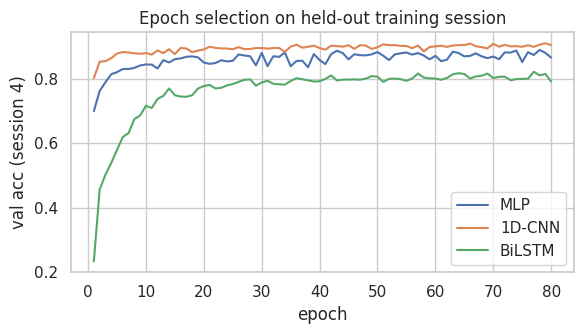

In [ ]:
hist_mlp  = run_dl("MLP", MLP, Xtr, Xte)
hist_cnn  = run_dl("1D-CNN", CNN1D, Str, Ste)
hist_lstm = run_dl("BiLSTM", BiLSTM, Str, Ste)

plt.figure(figsize=(6, 3.5))
for n, h in (("MLP", hist_mlp), ("1D-CNN", hist_cnn), ("BiLSTM", hist_lstm)):
    plt.plot(range(1, len(h) + 1), h, label=n)
plt.xlabel("epoch"); plt.ylabel("val acc (session 4)"); plt.legend(); plt.title("Epoch selection on held-out training session")
plt.tight_layout(); plt.show()

## 6. Ablations
Does hand-crafted feature engineering help, and does the answer depend on the model family?

LogReg (+derived)        acc=0.7013  macroF1=0.6979  (8s)
RandomForest (+derived)  acc=0.7959  macroF1=0.7918  (30s)
 reps_per_user  accuracy
            10    0.2671
            25    0.4058
            50    0.5130
           100    0.6410
           200    0.8163


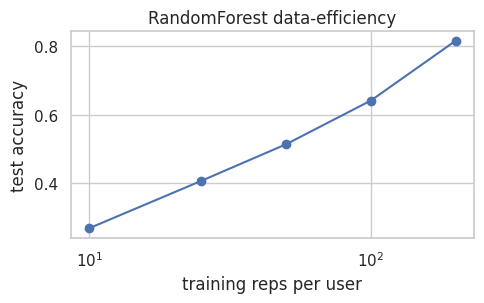

In [ ]:
Xtr_d, Xte_d = add_derived(train).values, add_derived(test).values
sc_d = StandardScaler().fit(Xtr_d)
run_sk("LogReg (+derived)", LogisticRegression(C=10, max_iter=3000), sc_d.transform(Xtr_d), sc_d.transform(Xte_d))
run_sk("RandomForest (+derived)", RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED), Xtr_d, Xte_d)

# Training-data size: accuracy of RandomForest vs. number of training reps per user (first n reps of sessions 1-4)
rows = []
for n in (10, 25, 50, 100, 200):
    keep = train.groupby("subject").cumcount().values < n
    m = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(Xtr[keep], ytr[keep])
    rows.append((n, accuracy_score(yte, m.predict(Xte))))
lc = pd.DataFrame(rows, columns=["reps_per_user", "accuracy"]); print(lc.round(4).to_string(index=False))
plt.figure(figsize=(5, 3.2)); plt.plot(lc.reps_per_user, lc.accuracy, "o-"); plt.xscale("log")
plt.xlabel("training reps per user"); plt.ylabel("test accuracy"); plt.title("RandomForest data-efficiency"); plt.tight_layout(); plt.show()

## 7. Error analysis (best model)

best model: 1D-CNN 0.8571

Accuracy by test session:
5    0.8961
6    0.8945
7    0.8396
8    0.7980

Hardest users (recall):
 37    0.310
54    0.395
32    0.450
16    0.585
2     0.595
21    0.615
31    0.620
47    0.650

Most confused (count, true -> predicted):
   55  54 -> 7
   48  29 -> 7
   45  27 -> 4
   42  16 -> 50
   39  21 -> 32
   36  32 -> 3
   31  37 -> 32
   30  54 -> 8


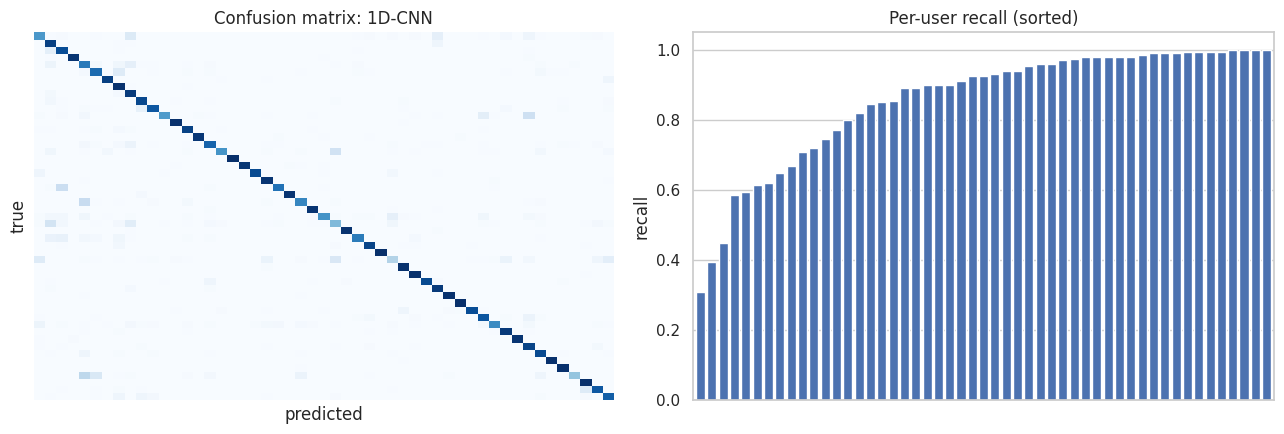

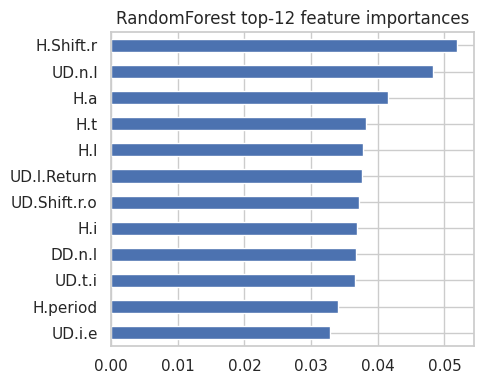

In [ ]:
best_name = max(RESULTS, key=lambda k: RESULTS[k]["accuracy"])
bp = RESULTS[best_name]["pred"]
print("best model:", best_name, round(RESULTS[best_name]["accuracy"], 4))

# accuracy by test session (drift check)
print("\nAccuracy by test session:")
print(pd.Series(bp == yte).groupby(test.sessionIndex.values).mean().round(4).to_string())

# per-user recall: hardest users, and most confused pairs
cm = confusion_matrix(yte, bp)
rec = pd.Series(np.diag(cm) / cm.sum(1), index=classes).sort_values()
print("\nHardest users (recall):\n", rec.head(8).round(3).to_string())
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], classes[i], classes[j]) for i in range(51) for j in range(51) if off[i, j] > 0), reverse=True)[:8]
print("\nMost confused (count, true -> predicted):")
for c, a, b in pairs: print(f"  {c:3d}  {a} -> {b}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, cmap="Blues", ax=axes[0], cbar=False, xticklabels=False, yticklabels=False)
axes[0].set_title(f"Confusion matrix: {best_name}"); axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true")
rec.plot.bar(ax=axes[1], width=0.8); axes[1].set_xticks([]); axes[1].set_ylabel("recall"); axes[1].set_title("Per-user recall (sorted)")
plt.tight_layout(); plt.show()

# what the forest uses
imp = pd.Series(MODELS["RandomForest"].feature_importances_, index=feat_cols).sort_values()
imp.tail(12).plot.barh(figsize=(5, 4), title="RandomForest top-12 feature importances"); plt.tight_layout(); plt.show()

## 8. Summary and saved artifacts

,accuracy,macro_f1
1D-CNN,0.8571,0.8534
MLP,0.8420,0.8386
RandomForest,0.8183,0.8144
XGBoost,0.8051,0.8028
RandomForest (+derived),0.7959,0.7918
SVM-RBF,0.7616,0.7573
BiLSTM,0.7492,0.7450
LogReg (+derived),0.7013,0.6979
LogisticRegression,0.6913,0.6854


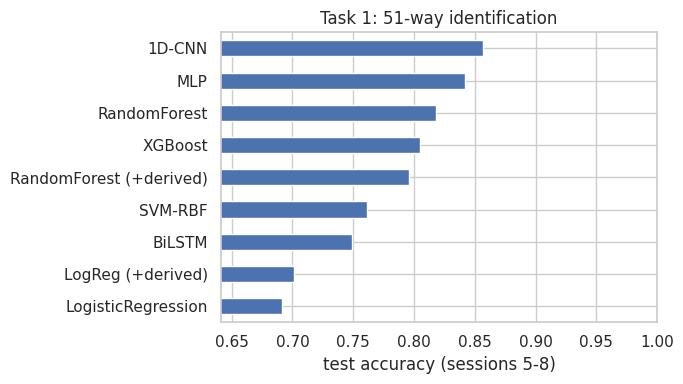

saved RandomForest -> /content/keystroke-dynamics-project/models/task1_best_classical.joblib
results rows for this task: 18


In [ ]:
import joblib
res = pd.DataFrame({k: {"accuracy": v["accuracy"], "macro_f1": v["macro_f1"]} for k, v in RESULTS.items()}).T.sort_values("accuracy", ascending=False)
display(res.round(4))

plt.figure(figsize=(7, 4))
res.accuracy.iloc[::-1].plot.barh(color="C0"); plt.xlim(max(0, res.accuracy.min() - 0.05), 1.0)
plt.xlabel("test accuracy (sessions 5-8)"); plt.title("Task 1: 51-way identification"); plt.tight_layout(); plt.show()

# Save the best sklearn/XGBoost model for the Streamlit tab (trained on sessions 1-4 only).
classical = [k for k in ("LogisticRegression", "SVM-RBF", "RandomForest", "XGBoost") if k in RESULTS]
bc = max(classical, key=lambda k: RESULTS[k]["accuracy"])
os.makedirs(os.path.join(ROOT, "models"), exist_ok=True)
joblib.dump({"name": bc, "model": MODELS[bc], "scaler": scaler, "classes": classes, "feat_cols": feat_cols},
            os.path.join(ROOT, "models", "task1_best_classical.joblib"))
print("saved", bc, "->", os.path.join(ROOT, "models", "task1_best_classical.joblib"))
print("results rows for this task:", (pd.read_csv(RESULTS_PATH).task == TASK).sum())